In [31]:
# import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import  Path
from statsmodels.graphics.tsaplots import plot_acf
import holidays

pd.set_option("display.max_columns", None)
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "processed"

In [32]:
#load the datasets
demand_path = DATA_DIR / "gb_demand_merged.parquet"
data = pd.read_parquet(demand_path)
df = data.copy()

In [33]:
df.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,is_imputed,datetime_local,local_date,local_time,elexon_forecast_published_utc,elexon_forecast,emb_solar_fc,emb_wind_fc,emb_fc_issued_utc,temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,shortwave_radiation,forecast_temperature_2m,forecast_relative_humidity_2m,forecast_precipitation,forecast_cloud_cover,forecast_wind_speed_10m,forecast_shortwave_radiation,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,2020-01-01,1,26253.0,False,2020-01-01 00:00:00+00:00,2020-01-01,00:00,NaT,NaN,0,1689,2019-12-21 02:12:00+00:00,4.888889,92.444444,0.0,81.555556,2.928889,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,0,0,1,1,0,1
2020-01-01 00:30:00+00:00,2020-01-01,2,26845.0,False,2020-01-01 00:30:00+00:00,2020-01-01,00:30,NaT,NaN,0,1696,2019-12-21 02:12:00+00:00,4.888889,92.444444,0.0,81.555556,2.928889,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,0,30,1,1,0,1
2020-01-01 01:00:00+00:00,2020-01-01,3,26440.0,False,2020-01-01 01:00:00+00:00,2020-01-01,01:00,NaT,NaN,0,1696,2019-12-21 02:12:00+00:00,4.888889,92.666667,0.0,87.555556,2.727778,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,1,0,1,1,0,1
2020-01-01 01:30:00+00:00,2020-01-01,4,25631.0,False,2020-01-01 01:30:00+00:00,2020-01-01,01:30,NaT,NaN,0,1703,2019-12-21 02:12:00+00:00,4.888889,92.666667,0.0,87.555556,2.727778,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,1,30,1,1,0,1
2020-01-01 02:00:00+00:00,2020-01-01,5,24947.0,False,2020-01-01 02:00:00+00:00,2020-01-01,02:00,NaT,NaN,0,1703,2019-12-21 02:12:00+00:00,5.011111,92.555556,0.0,93.555556,2.661111,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,2,0,1,1,0,1


In [34]:
#check missing values in the merged dataset
df.isnull().sum()

SETTLEMENT_DATE                      0
SETTLEMENT_PERIOD                    0
ND                                   0
is_imputed                           0
datetime_local                       0
local_date                           0
local_time                           0
elexon_forecast_published_utc    26612
elexon_forecast                  26612
emb_solar_fc                         0
emb_wind_fc                          0
emb_fc_issued_utc                    0
temperature_2m                       0
relative_humidity_2m                 0
precipitation                        0
cloud_cover                          0
wind_speed_10m                       0
shortwave_radiation                  0
forecast_temperature_2m          78864
forecast_relative_humidity_2m    78864
forecast_precipitation           78864
forecast_cloud_cover             79122
forecast_wind_speed_10m          78864
forecast_shortwave_radiation     78864
year                                 0
month                    

In [35]:
#check summary statistics of the dataset
df.describe().round(2)

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,local_date,elexon_forecast,emb_solar_fc,emb_wind_fc,temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,shortwave_radiation,forecast_temperature_2m,forecast_relative_humidity_2m,forecast_precipitation,forecast_cloud_cover,forecast_wind_speed_10m,forecast_shortwave_radiation,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday
count,119952,119952.00,119952.00,119952,93340.00,119952.00,119952.00,119952.00,119952.00,119952.00,119952.00,119952.00,119952.00,41088.00,41088.00,41088.00,40830.00,41088.00,41088.00,119952.00,119952.00,119952.0,119952.00,119952.0,119952.00,119952.00,119952.00,119952.00
mean,2023-06-03 00:35:47.899159,24.50,26560.29,2023-06-03 00:35:47.899159,26231.92,1620.90,1804.83,11.14,80.58,0.10,70.19,4.22,118.88,11.59,79.39,0.10,58.12,3.77,133.00,2022.93,6.41,3.0,11.50,15.0,179.61,2.47,0.29,0.03
min,2020-01-01 00:00:00,1.00,12621.00,2020-01-01 00:00:00,12080.00,0.00,174.00,-4.58,28.44,0.00,0.00,0.67,0.00,-3.37,31.89,0.00,0.00,0.69,0.00,2020.00,1.00,0.0,0.00,0.0,1.00,1.00,0.00,0.00
25%,2021-09-16 00:00:00,12.75,21773.00,2021-09-16 00:00:00,21580.00,0.00,912.00,7.19,74.33,0.00,53.11,2.80,0.00,7.31,71.56,0.00,36.67,2.58,0.00,2021.00,3.00,1.0,5.75,0.0,90.00,1.00,0.00,0.00
50%,2023-06-03 00:00:00,24.50,25646.50,2023-06-03 00:00:00,25330.00,50.00,1548.00,10.99,83.78,0.02,76.22,3.90,7.00,11.57,82.78,0.02,60.00,3.53,10.89,2023.00,6.00,3.0,11.50,15.0,179.00,2.00,0.00,0.00
75%,2025-02-17 00:00:00,36.25,30397.00,2025-02-17 00:00:00,29858.25,2633.25,2468.00,15.02,89.33,0.11,92.22,5.34,190.56,15.62,89.44,0.11,81.33,4.73,220.44,2025.00,9.00,5.0,17.25,30.0,268.00,3.00,1.00,0.00
max,2026-11-03 00:00:00,50.00,47319.00,2026-11-03 00:00:00,46820.00,14621.00,5906.00,33.09,99.00,2.30,100.00,13.17,873.33,31.48,98.56,2.47,100.00,10.95,845.44,2026.00,12.00,6.0,23.00,30.0,366.00,4.00,1.00,1.00
std,NaN,13.85,6155.32,NaN,6034.36,2501.38,1113.52,5.44,11.61,0.20,25.58,1.83,178.18,5.71,12.70,0.20,27.45,1.55,192.82,1.97,3.40,2.0,6.92,15.0,103.99,1.11,0.45,0.16


In [36]:
#check summary statistics for the demand column for each year
df[['ND','year']].groupby(by ='year')['ND'].agg(Mean ='mean',STD ='std', Max ='max',Min ='min').round()

,Mean,STD,Max,Min
year,,,,
2020,27115.0,6617.0,45885.0,13368.0
2021,28308.0,6050.0,46342.0,16312.0
2022,26587.0,6103.0,46042.0,15080.0
2023,26015.0,5969.0,43998.0,13598.0
2024,26251.0,5938.0,45096.0,15074.0
2025,26121.0,6145.0,45851.0,12812.0
2026,25327.0,5736.0,47319.0,12621.0


In [37]:
#check for duplicates
duplicate_rows  = df.index.duplicated().sum()
print(duplicate_rows)

0


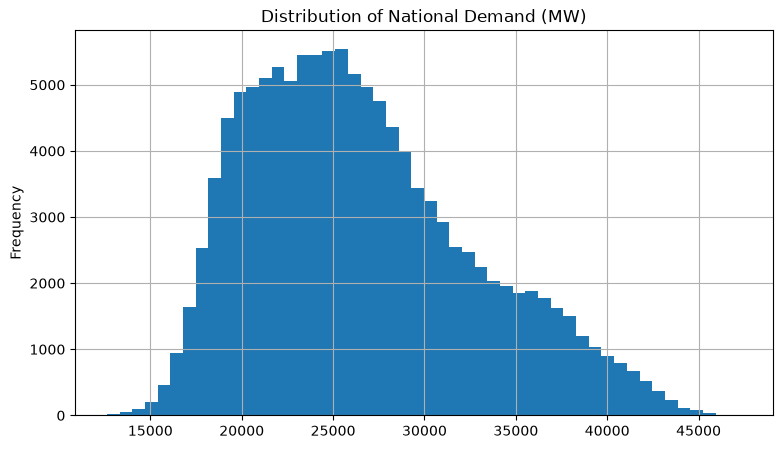

In [38]:

#check demand distribution 
plt.figure(figsize = (9,5))
df['ND'].hist(bins = 50)
plt.title("Distribution of National Demand (MW)")
plt.ylabel("Frequency")
plt.show()


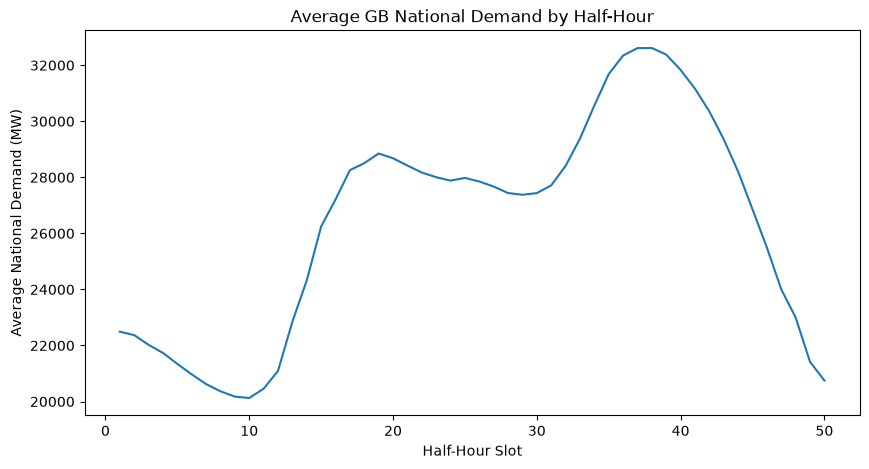

In [39]:
half_hourly_demand = df.groupby("SETTLEMENT_PERIOD")["ND"].mean()


#half_hourly_demand = df.groupby("half_hour_slot")["ND"].mean()

half_hourly_demand.plot(figsize=(10, 5))
plt.title("Average GB National Demand by Half-Hour")
plt.xlabel("Half-Hour Slot")
plt.ylabel("Average National Demand (MW)")
plt.show()

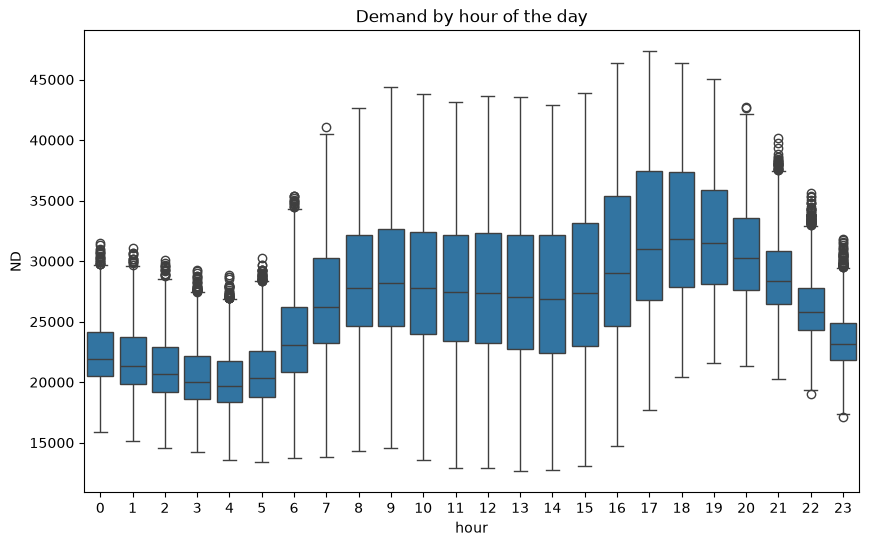

In [40]:
#Demand was quite low during the periods between 3 am to 5 am
#Demand started rising after 5 am and plateaued at 10 am before rising and peaking at around 6pm
# demand kept falling from evening to morning 

plt.figure(figsize = (10,6))
sns.boxplot(data = df,x = 'hour', y='ND',)
plt.title('Demand by hour of the day')
plt.show()


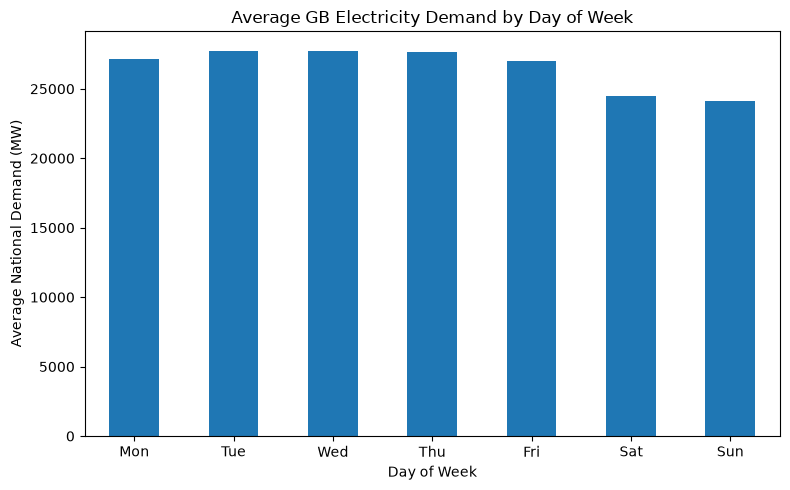

In [41]:
#weekly pattern
daily_avg = df.groupby('day_of_week')['ND'].mean()

#plotting the average demand for each day of the week
days = ["Mon", "Tue", "Wed","Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(8, 5))
daily_avg.plot(kind="bar", ax=ax)
ax.set_xticks(range(len(days)))
ax.set_xticklabels(days, rotation=0)
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average National Demand (MW)")
ax.set_title("Average GB Electricity Demand by Day of Week")

plt.tight_layout()
plt.show()


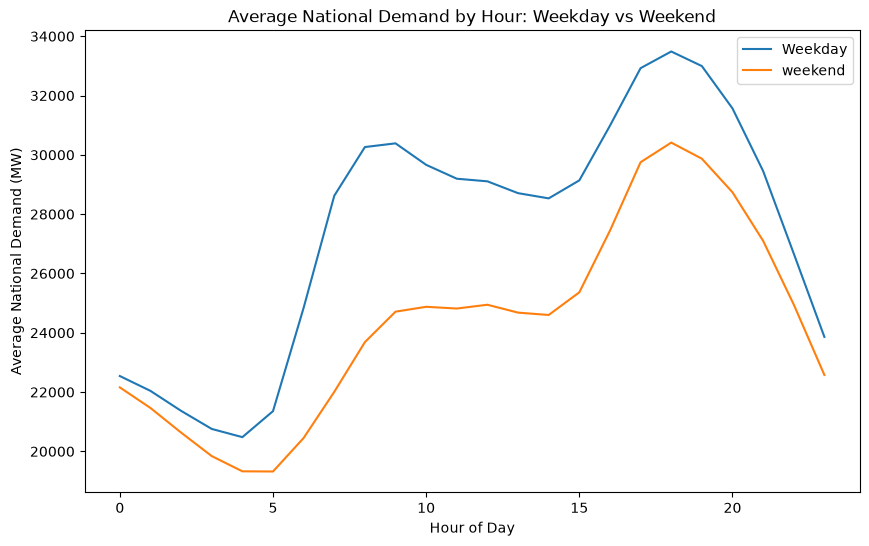

In [42]:

#check hourly average demand for weekdays and weekends
weekday_hourly = df[df["is_weekend"] == 0].groupby("hour")["ND"].mean()
weekend_hourly = df[df["is_weekend"] == 1].groupby("hour")["ND"].mean()


fig, ax = plt.subplots(figsize = (10,6))
weekday_hourly.plot(ax=ax, label= 'Weekday')
weekend_hourly.plot(ax=ax,label= 'weekend')

ax.set_title("Average National Demand by Hour: Weekday vs Weekend")
ax.set_ylabel("Average National Demand (MW)")
ax.set_xlabel("Hour of Day")
plt.legend()
plt.show()

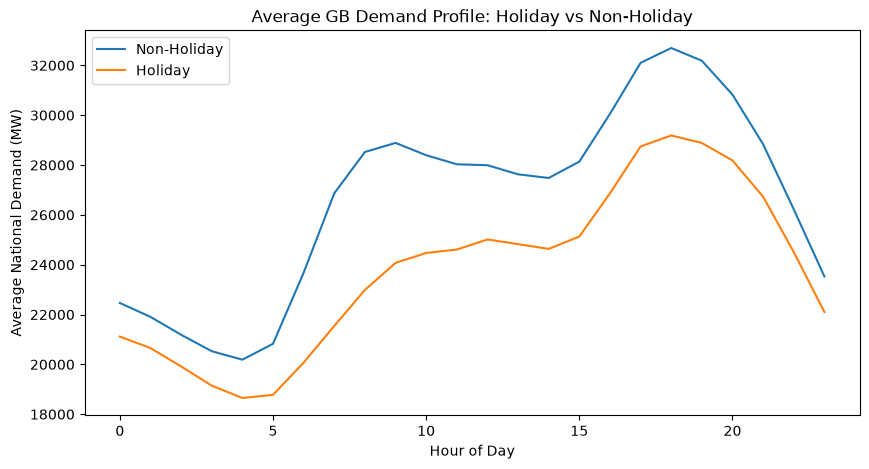

In [43]:
holiday_hourly = (
    df.groupby(["is_holiday", "hour"])["ND"]
    .mean()
    .unstack(level=0)
)

holiday_hourly.columns = [
    "Non-Holiday",
    "Holiday"
]

holiday_hourly.plot(figsize=(10, 5))

plt.title("Average GB Demand Profile: Holiday vs Non-Holiday")
plt.xlabel("Hour of Day")
plt.ylabel("Average National Demand (MW)")
plt.show()

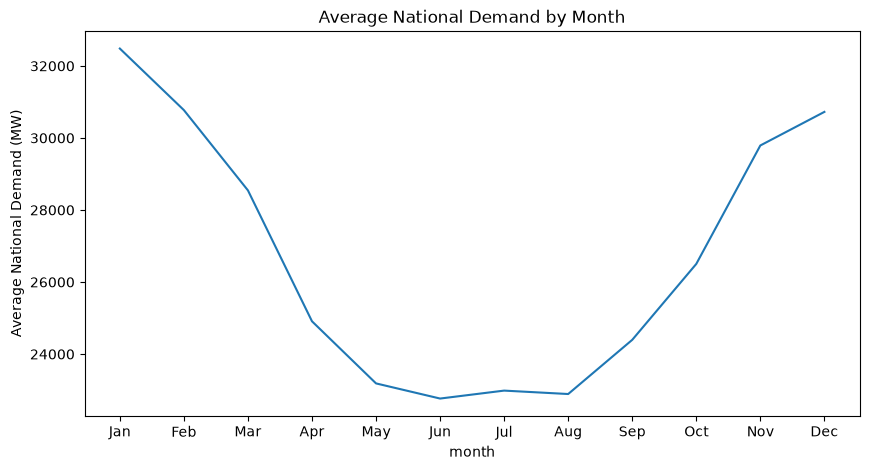

In [44]:
#monthly pattern
monthly_avg = df.groupby("month")["ND"].mean()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun","Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize =(10,5))
monthly_avg.plot(ax=ax)
ax.set_xticks(monthly_avg.index)
ax.set_xticklabels(months, rotation = 0)
ax.set_title("Average National Demand by Month")
ax.set_ylabel("Average National Demand (MW)")
plt.show()

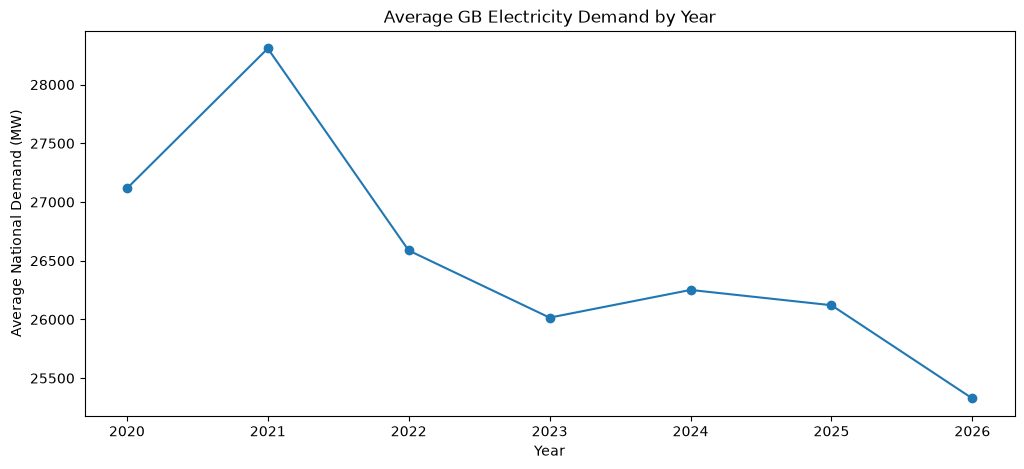

In [45]:
#yearly demand 
yearly_avg = df.groupby("year")["ND"].mean()


fig, ax = plt.subplots(figsize=(12,5))

yearly_avg.plot(ax=ax,marker="o")

ax.set_title("Average GB Electricity Demand by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Average National Demand (MW)")
plt.show()

In [46]:


#Plot demand vs weather variables
def plot_demand_vs_weather(df, variable_list):
    length = len(variable_list)
    fig, axes = plt.subplots(figsize=(10,6*length), nrows=length, ncols=1)
    for ax,variable in zip(axes,variable_list):
        sns.scatterplot(data=df, x=variable, y="ND",ax=ax)
        ax.set_title(f"{variable} vs National Demand")
        ax.set_xlabel(variable)
        ax.set_ylabel("National Demand (MW)")


    plt.tight_layout()
    plt.show()

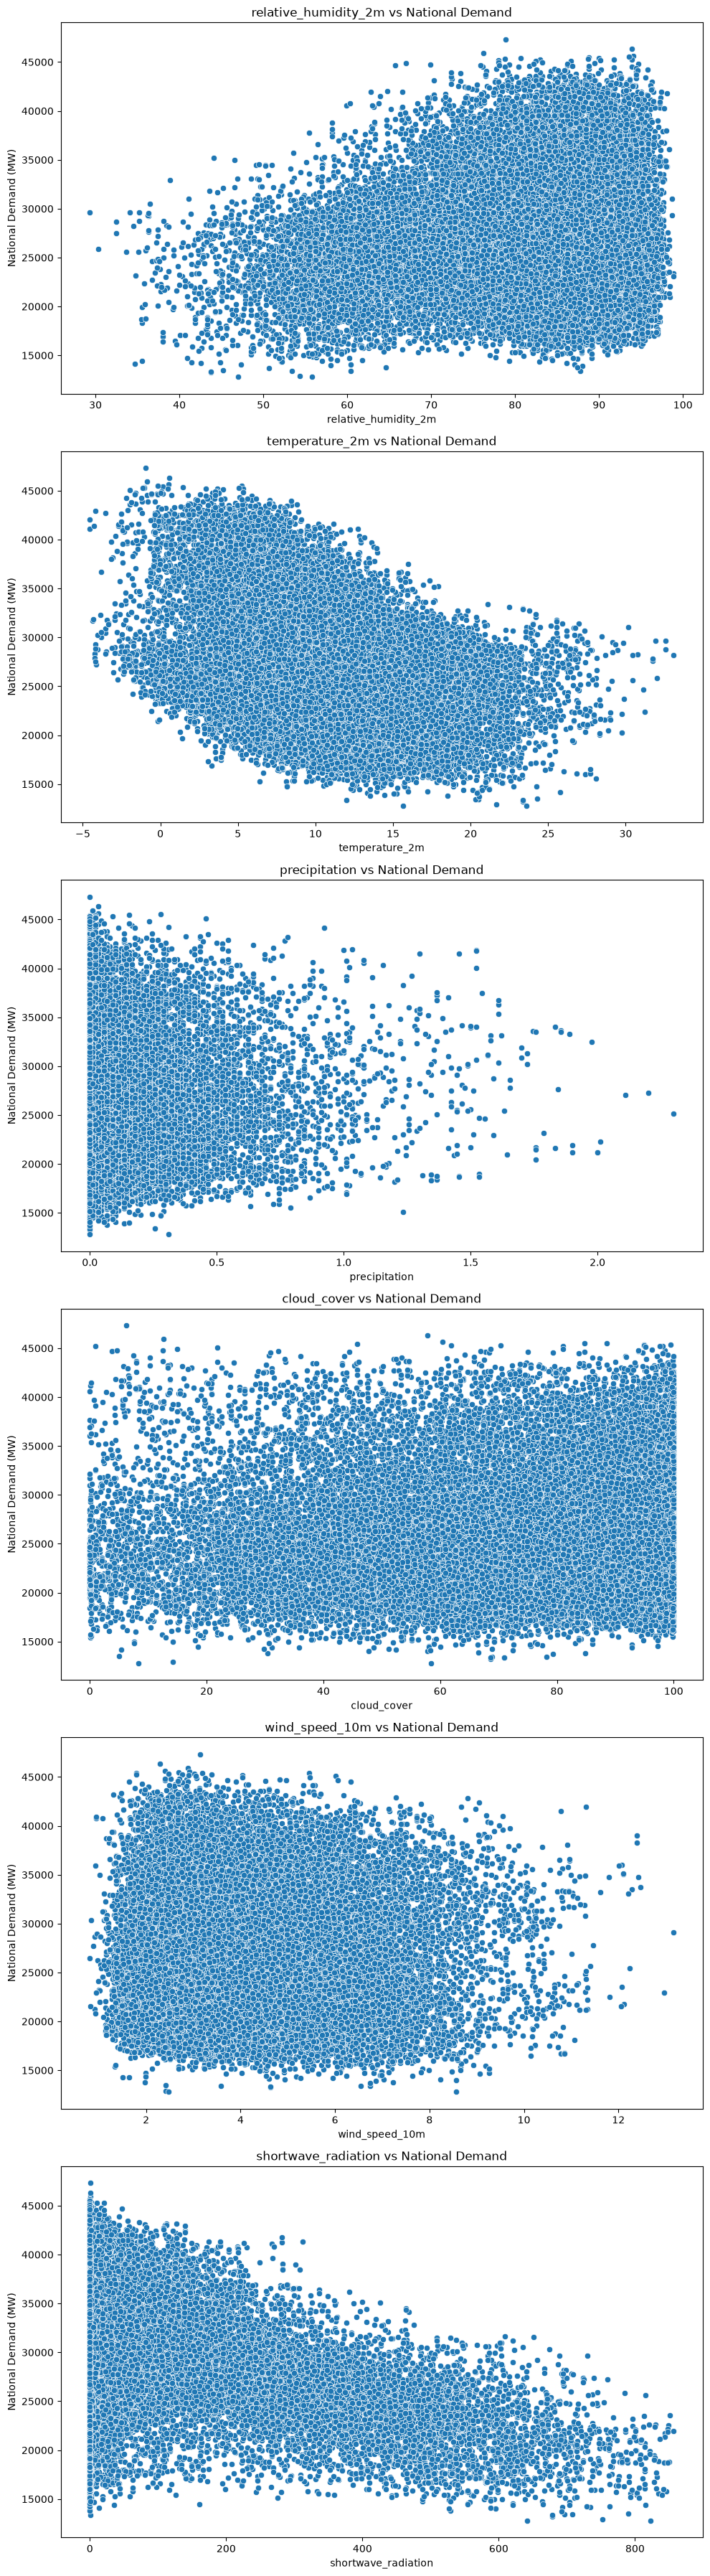

In [47]:

variable_list =["relative_humidity_2m","temperature_2m","precipitation",
                "cloud_cover","wind_speed_10m","shortwave_radiation",]

df_sample = df.sample(n=min(30000,len(df)), random_state=42) 
plot_demand_vs_weather(df_sample, variable_list)

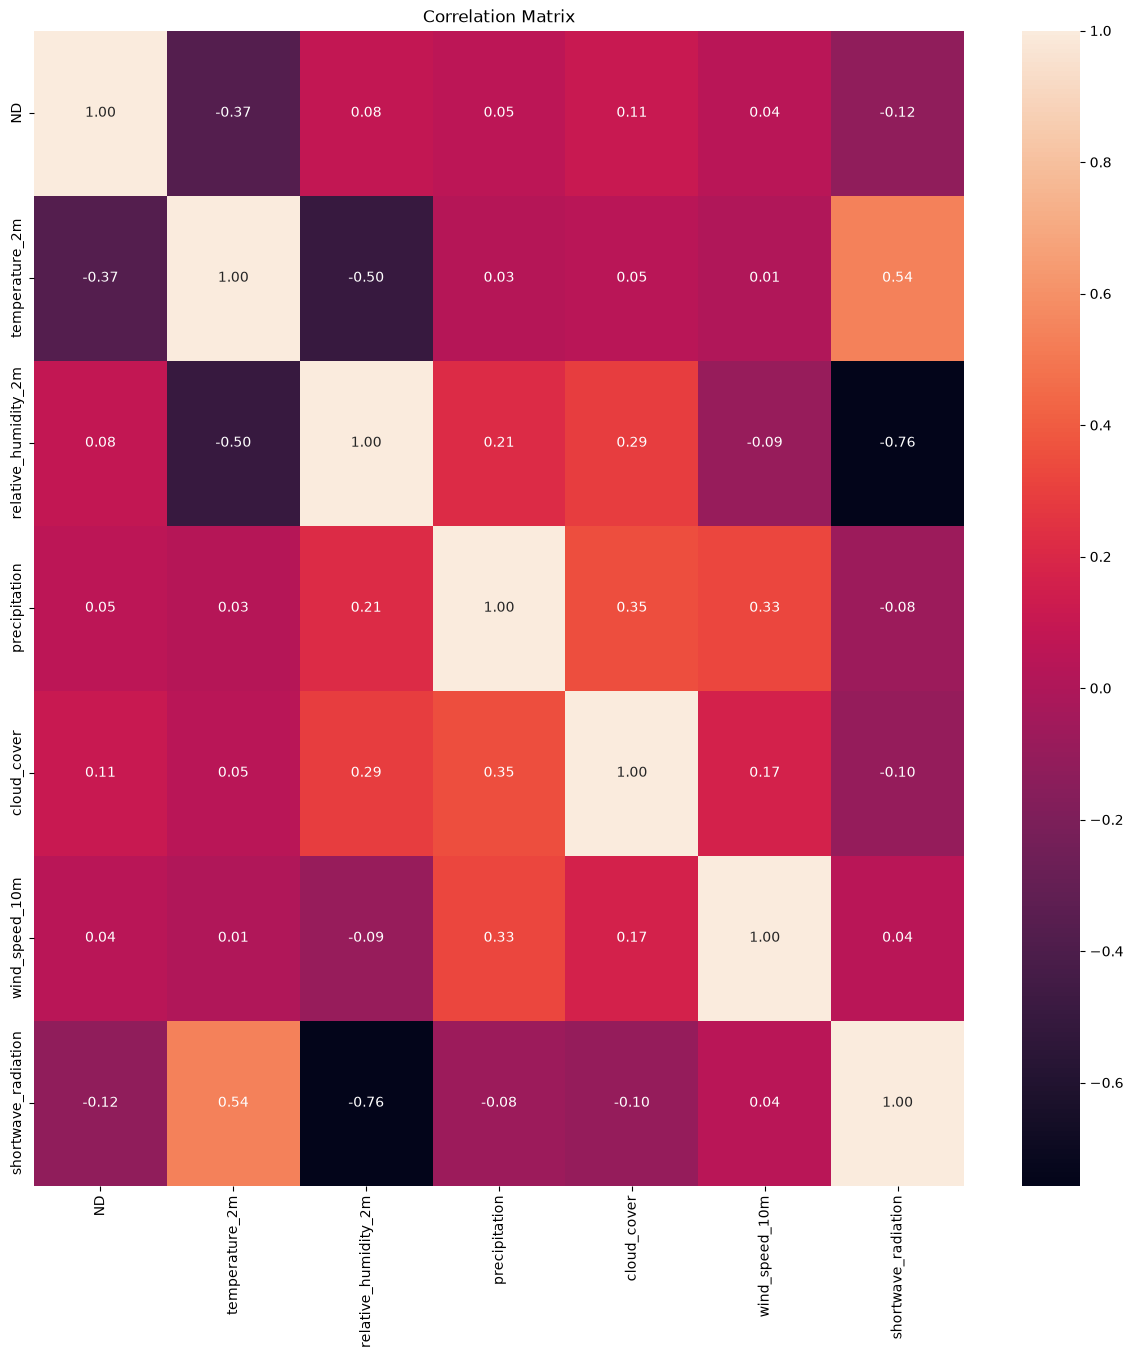

In [48]:
# check correlation
col = ['ND','temperature_2m', 'relative_humidity_2m', 'precipitation', 'cloud_cover',
       'wind_speed_10m', 'shortwave_radiation']

plt.figure(figsize=(15,15))
sns.heatmap(df[col].corr(),annot=True,fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

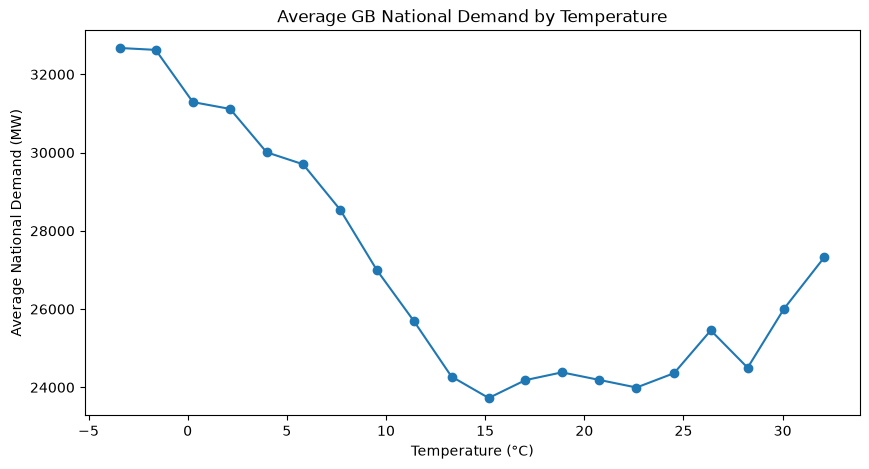

In [49]:
#check relationship between temperature and demand
temp_bins = pd.cut(df["temperature_2m"],bins=20)

temp_demand = (df.groupby(temp_bins, observed=True)
               .agg(temperature=("temperature_2m", "mean"),demand=("ND", "mean")))

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(temp_demand["temperature"],temp_demand["demand"],marker="o")

ax.set_title("Average GB National Demand by Temperature")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Average National Demand (MW)")

plt.show()

In [50]:
# check autocorrelation for seasonal lags (1 day to 7 days)
seasonal_lags = [48, 96, 144, 192, 240, 288, 336, 17472]

for lag in seasonal_lags:
    print(f"Lag {lag} {df['ND'].autocorr(lag=lag):.3f}")

Lag 48 0.911
Lag 96 0.836
Lag 144 0.809
Lag 192 0.801
Lag 240 0.810
Lag 288 0.862
Lag 336 0.900
Lag 17472 0.893
